# Land cover and mapped building exposure

Land cover characterises the surface. Mapped buildings describe potentially exposed assets; neither building presence nor overlap with a model water mask establishes damage.

WorldCover v200 describes 2021 at 10m. Open Buildings v3 was inferred in May 2023; it is not a verified August 2022 inventory. A fixed **confidence ≥0.75** filter is applied before inspection. This score concerns building detection, not flooding or local calibrated detection accuracy.

Detections are assigned by centroid to one 100m cell. A separate rasterized footprint occupancy is a 10m proxy, not exact footprint area. Polygon occupancy can include buildings whose centroids fall outside the ROI; centroid counts and occupancy therefore have different boundary conventions. Source omissions, false detections and publication timing remain relevant. Empty cells mean no retained mapped detections, not verified absence of buildings.

All features remain unlabelled. Do not claim risk, population, occupancy of buildings, or flood damage from this map.

In [1]:
import os
import sys
from pathlib import Path

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT))


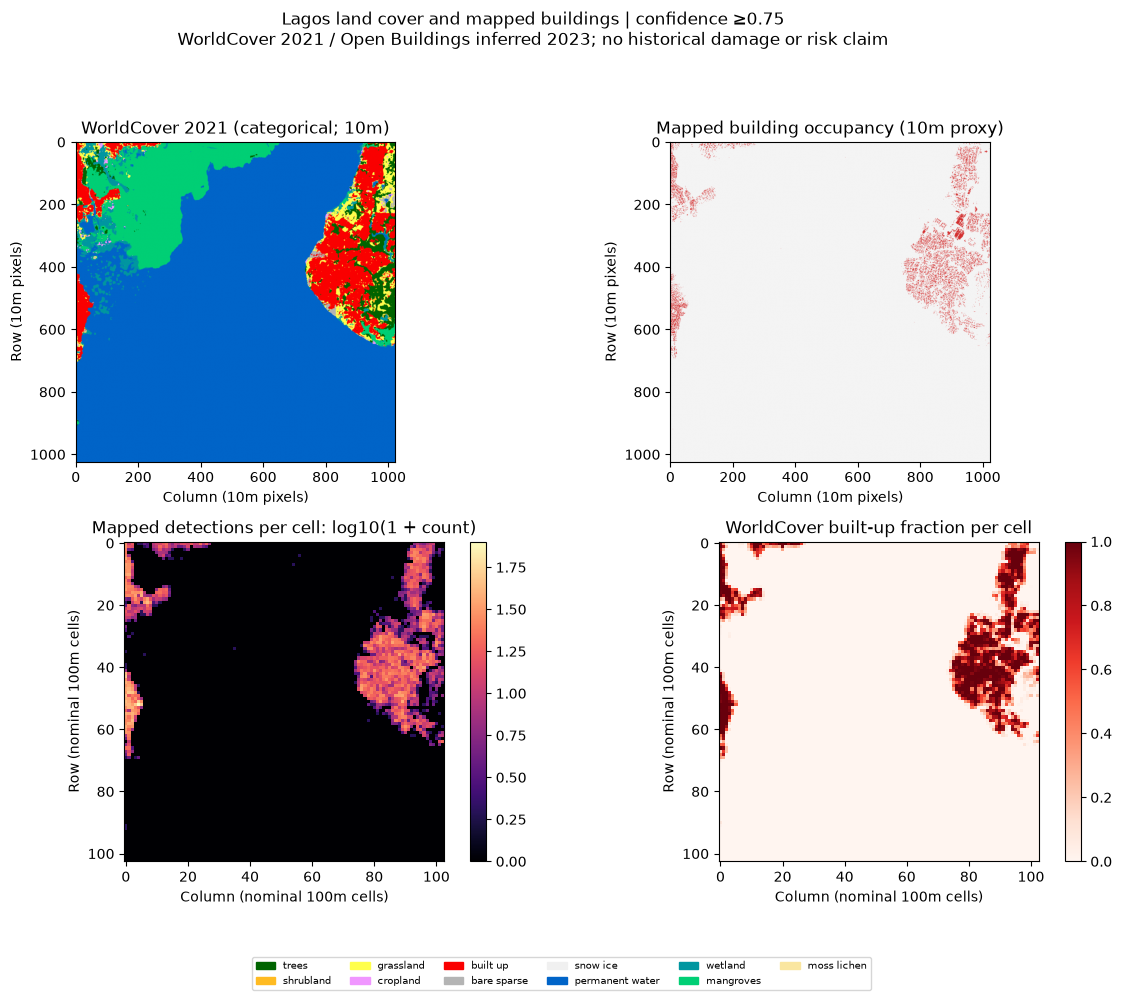

Joined cells: 10609 Mapped detections: 17206


In [2]:
import csv
import json
import shutil
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap,BoundaryNorm
from matplotlib.patches import Patch
from floodrisk.acquire.surface import CLASSES
from floodrisk.deploy.tiled import file_hash

source=PROJECT / "data/surface/lagos_first"
out=PROJECT / "reports/lagos_2022/surface"
out.mkdir(exist_ok=True)
for name in ["surface.json","cell_schema.json","building_centroid_counts.json"]:shutil.copy2(source/name,out/name)
report=json.loads((out/"surface.json").read_text())
assert file_hash(source/"surface_features.tif")==report["sha256"]
with rasterio.open(source/"surface_features.tif") as src:
    cover,occupancy=src.read(masked=True)
    surface_grid=src.crs,src.transform,src.shape
with rasterio.open(PROJECT/"data/terrain/lagos_first/terrain_features.tif") as src:
    assert surface_grid==(src.crs,src.transform,src.shape)
with (source/"combined_cells_100m.csv").open() as f:cells=list(csv.DictReader(f))
assert len(cells)==10609
assert sum(int(c["mapped_building_centroid_count"]) for c in cells)==report["building_detections_with_centroid_in_roi"]
assert sum(int(c["pixels"]) for c in cells)==1024*1024
for cell in cells:
    if float(cell["worldcover_valid_fraction"])>0:
        assert abs(sum(float(cell[f"cover_{name}_fraction"]) for name in CLASSES.values())-1)<1e-9
with (out/"cell_sample.csv").open("w") as f:
    writer=csv.DictWriter(f,fieldnames=list(cells[0]));writer.writeheader();writer.writerows(cells[:10])
count_grid=np.zeros((103,103));built_grid=np.full((103,103),np.nan)
for c in cells:
    r,col=int(c["cell_row"]),int(c["cell_col"])
    count_grid[r,col]=int(c["mapped_building_centroid_count"])
    if c["cover_built_up_fraction"]:built_grid[r,col]=float(c["cover_built_up_fraction"])
colors=["#006400","#ffbb22","#ffff4c","#f096ff","#fa0000","#b4b4b4","#f0f0f0","#0064c8","#0096a0","#00cf75","#fae6a0"]
indexed=np.full(cover.shape,-1,dtype="int16")
for i,code in enumerate(CLASSES):indexed[np.asarray(cover.data)==code]=i
indexed=np.ma.masked_where(np.ma.getmaskarray(cover)|(indexed<0),indexed)
assert indexed.count()==cover.count()
fig,axes=plt.subplots(2,2,figsize=(12,10))
axes[0,0].imshow(indexed,cmap=ListedColormap(colors),norm=BoundaryNorm(np.arange(-0.5,11.5),11))
axes[0,0].set_title("WorldCover 2021 (categorical; 10m)")
axes[0,1].imshow(occupancy,cmap=ListedColormap(["#f4f4f4","#d32f2f"]),vmin=0,vmax=1)
axes[0,1].set_title("Mapped building occupancy (10m proxy)")
image=axes[1,0].imshow(np.log10(1+count_grid),cmap="magma")
axes[1,0].set_title("Mapped detections per cell: log10(1 + count)")
fig.colorbar(image,ax=axes[1,0],fraction=0.046)
image=axes[1,1].imshow(built_grid,cmap="Reds",vmin=0,vmax=1)
axes[1,1].set_title("WorldCover built-up fraction per cell")
fig.colorbar(image,ax=axes[1,1],fraction=0.046)
for i,ax in enumerate(axes.flat):
    unit="10m pixels" if i<2 else "nominal 100m cells"
    ax.set_xlabel("Column ("+unit+")");ax.set_ylabel("Row ("+unit+")")
fig.legend(handles=[Patch(color=color,label=name.replace("_"," ")) for color,name in zip(colors,CLASSES.values())],
    loc="lower center",ncol=6,fontsize=7)
fig.suptitle("Lagos land cover and mapped buildings | confidence ≥0.75\nWorldCover 2021 / Open Buildings inferred 2023; no historical damage or risk claim")
fig.tight_layout(rect=[0,0.07,1,0.94]);fig.savefig(out/"surface_features.png",dpi=150,bbox_inches="tight")
plt.show();plt.close(fig)
print("Joined cells:",len(cells),"Mapped detections:",int(count_grid.sum()))
